In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Semua library berhasil di-import!")

Semua library berhasil di-import!


In [9]:
np.random.seed(42)
n_samples = 300

suhu = np.random.uniform(20.0, 40.0, n_samples)          # °C
kelembapan = np.random.uniform(30.0, 80.0, n_samples)    # %
gas_ppm = np.random.uniform(100.0, 800.0, n_samples)     # PPM

target = np.where((gas_ppm > 450) | ((gas_ppm > 350) & (suhu > 32.0)), 1, 0)

df_sensor = pd.DataFrame({
    'Suhu': suhu,
    'Kelembapan': kelembapan,
    'Gas_PPM': gas_ppm,
    'Status_Bahaya': target
})

df_sensor.loc[np.random.choice(df_sensor.index, 10), 'Suhu'] = np.nan
df_sensor.loc[np.random.choice(df_sensor.index, 10), 'Gas_PPM'] = np.nan

print("--- 5 Baris Pertama Dataset Sensor ---")
print(df_sensor.head())
print("\nUkuran Dataset:", df_sensor.shape)

--- 5 Baris Pertama Dataset Sensor ---
        Suhu  Kelembapan     Gas_PPM  Status_Bahaya
0  27.490802   32.584086  218.254544              0
1        NaN   56.567732  295.013237              0
2  34.639879   57.031756  223.907339              0
3  31.973170   61.871495  162.091774              0
4  23.120373   66.304567  184.445110              0

Ukuran Dataset: (300, 4)


In [10]:
print("=== Jumlah Missing Value per Kolom ===")
print(df_sensor.isnull().sum())

imputer = SimpleImputer(strategy='median')
df_sensor[['Suhu', 'Kelembapan', 'Gas_PPM']] = imputer.fit_transform(df_sensor[['Suhu', 'Kelembapan', 'Gas_PPM']])

print("\n=== Setelah Imputasi Missing Value ===")
print(df_sensor.isnull().sum())

=== Jumlah Missing Value per Kolom ===
Suhu             10
Kelembapan        0
Gas_PPM          10
Status_Bahaya     0
dtype: int64

=== Setelah Imputasi Missing Value ===
Suhu             0
Kelembapan       0
Gas_PPM          0
Status_Bahaya    0
dtype: int64


In [11]:
X = df_sensor[['Suhu', 'Kelembapan', 'Gas_PPM']]
y = df_sensor['Status_Bahaya']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Data Training : {X_train_scaled.shape[0]} sampel")
print(f"Data Testing  : {X_test_scaled.shape[0]} sampel")

Data Training : 240 sampel
Data Testing  : 60 sampel


In [12]:
model_logreg = LogisticRegression(random_state=42)
model_logreg.fit(X_train_scaled, y_train)

model_dt = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model_dt.fit(X_train, y_train) 

model_rf = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=42)
model_rf.fit(X_train, y_train)

print("Seluruh Model Berhasil Dilatih!")

Seluruh Model Berhasil Dilatih!


=== PERBANDINGAN AKURASI MODEL BASELINE ===
1. Logistic Regression : 90.00%
2. Decision Tree       : 93.33%
3. Random Forest       : 88.33%

=== CLASSIFICATION REPORT (DECISION TREE) ===
              precision    recall  f1-score   support

        Aman       0.90      0.96      0.93        28
      Bahaya       0.97      0.91      0.94        32

    accuracy                           0.93        60
   macro avg       0.93      0.94      0.93        60
weighted avg       0.94      0.93      0.93        60



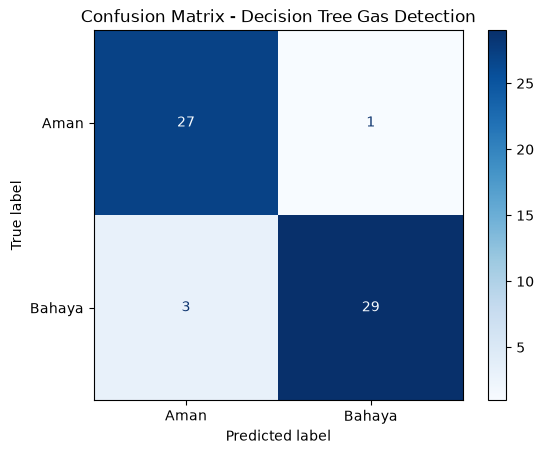

In [13]:
y_pred_logreg = model_logreg.predict(X_test_scaled)
y_pred_dt = model_dt.predict(X_test)
y_pred_rf = model_rf.predict(X_test)

print("=== PERBANDINGAN AKURASI MODEL BASELINE ===")
print(f"1. Logistic Regression : {accuracy_score(y_test, y_pred_logreg) * 100:.2f}%")
print(f"2. Decision Tree       : {accuracy_score(y_test, y_pred_dt) * 100:.2f}%")
print(f"3. Random Forest       : {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n")

print("=== CLASSIFICATION REPORT (DECISION TREE) ===")
print(classification_report(y_test, y_pred_dt, target_names=['Aman', 'Bahaya']))

cm = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Aman', 'Bahaya'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Decision Tree Gas Detection")
plt.show()

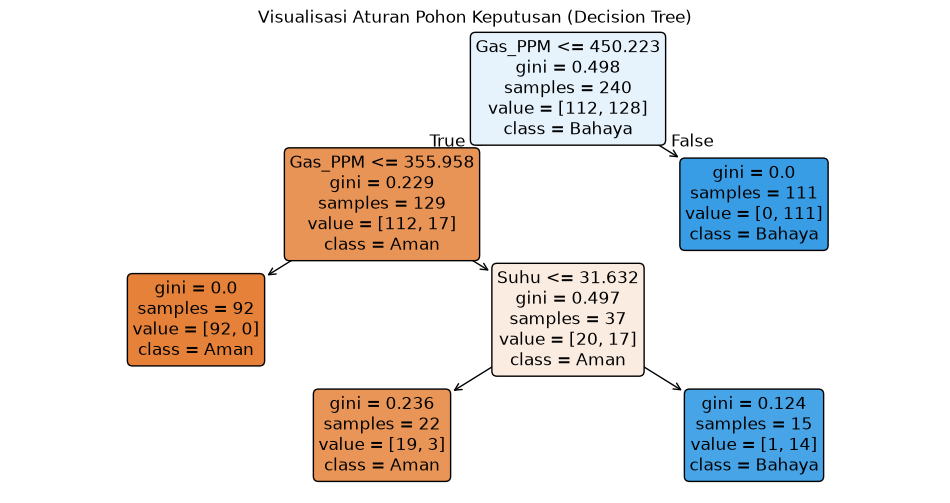

In [7]:
plt.figure(figsize=(12, 6))
plot_tree(
    model_dt, 
    feature_names=X.columns, 
    class_names=['Aman', 'Bahaya'], 
    filled=True, 
    rounded=True
)
plt.title("Visualisasi Aturan Pohon Keputusan (Decision Tree)")
plt.show()

In [16]:
data_sensor_baru = pd.DataFrame([
    [25.0, 60.0, 200.0],  # Sampel 1: Kondisi Normal
    [35.0, 40.0, 600.0]   # Sampel 2: Kondisi Bahaya
], columns=['Suhu', 'Kelembapan', 'Gas_PPM'])

prediksi_baru = model_dt.predict(data_sensor_baru)

print("=== HASIL PREDIKSI DATA SENSOR BARU ===")
for idx, pred in enumerate(prediksi_baru):
    status = "⚠️ BAHAYA KEBOCORAN GAS!" if pred == 1 else "✅ KONDISI AMAN"
    pembacaan = data_sensor_baru.iloc[idx].to_dict()
    print(f"Pembacaan Sensor {pembacaan} -> Status: {status}")

=== HASIL PREDIKSI DATA SENSOR BARU ===
Pembacaan Sensor {'Suhu': 25.0, 'Kelembapan': 60.0, 'Gas_PPM': 200.0} -> Status: ✅ KONDISI AMAN
Pembacaan Sensor {'Suhu': 35.0, 'Kelembapan': 40.0, 'Gas_PPM': 600.0} -> Status: ⚠️ BAHAYA KEBOCORAN GAS!
